# How well does ICESat-2 measure vegetation height across the boreal and Arctic, and how much did relabelling its photons help?

**For readers outside the ICESat-2 community.** NASA's ICESat-2 satellite measures the height of the land surface by timing
single laser photons. Along each orbit it records the ground, the vegetation, and many stray photons of sunlight. To turn those
photons into vegetation height, each photon is labelled ground, vegetation or noise, and the labelled photons are grouped into
30 m stretches along the orbit. The vegetation height of a stretch is the 98th percentile of its vegetation photons above the
ground.

Our forest biomass maps for the circumpolar boreal and tundra are trained on these 30 m heights, built from NASA's standard photon
labels (the ATL08 product). In our region those heights have two known problems: they **invent vegetation over bare ground and
tundra** (ground and sunlight photons labelled as vegetation), and they **miss tall forest** or call it bare ground. We therefore
relabelled the photons ourselves, in six steps (versions v0.1–v0.6), and checked every version against **airborne lidar, drone
surveys and field measurements**, which measure vegetation height to within tens of centimetres.

**How to read the figures**
- **Gray = today**: the heights our biomass models use now (NASA's photon labels).
- **Blue = our relabelled versions**, light to dark in the order we built them; **darkest blue = v0.6, the final version**.
- **Bias** = ICESat-2 height minus the lidar or drone height of the same 30 m stretch. Positive = too tall, negative = too short.
- **Independent references** (LVIS, CanElevation) were never used to design or tune any version, so they show how the method
  will do elsewhere. The **development sites** (G-LiHT, Seward drone transects and field heights) were used to build it.
- Unless stated, each comparison uses the same 30 m stretches for every version ("common segments"), so differences between
  versions are not caused by comparing different places.

![What the version names mean](../../docs/figures/terms_diagram.png)
- **LVIS carries less weight** than the other references: it is a full-waveform lidar whose noise floor is probably
  0.5–1.0 m (to be verified), so it cannot measure short vegetation reliably. Its results are shown, but versions are
  judged first on the discrete-return lidar (CanElevation, G-LiHT) and the drone surveys.


In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, validation_lib as val, plot_style as ps, presentation_lib as pl
ps.apply()
plt.rcParams.update({"font.family": "sans-serif", "axes.titleweight": "normal"})
cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")
WORK = Path(cfg["paths"]["work_dir"]); FIG = WORK / "runs" / f"v{cfg['version']}" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
d = pl.load_all(WORK)
S = pl.summary(d); K = pl.by_class(d)
S.to_csv(FIG.parent / "summary_all_references.csv", index=False); K.to_csv(FIG.parent / "by_class_all_references.csv", index=False)

## Where the heights were checked

In [2]:
t = (d.groupby("reference").agg(segments=("ref_h", "size"), regions=("region", "nunique"),
                                median_reference_height_m=("ref_h", "median"), day_share=("light", lambda s: (s == "day").mean()))
     .reindex(pl.REFS).assign(role=lambda x: [pl.REF_NOTE[r] for r in x.index]))
t.round(2)

,segments,regions,median_reference_height_m,day_share,role
reference,,,,,
LVIS 2019,36574,5,2.24,0.70,airborne waveform lidar · Alaska + W Canada · ...
CanElevation lidar,13972,13,1.27,0.67,airborne lidar · 13 provinces / territories · ...
G-LiHT lidar,2762,2,3.29,0.68,"airborne lidar · interior Alaska, Kenai · deve..."
Seward UAV,494,1,0.85,0.83,drone surface model · Seward Peninsula tundra ...
Seward field (2 m),184,1,1.23,0.88,"field heights, tallest within 2 m of each poin..."


**Map.** Every reference in one place. Independent references (filled markers) were never used to design or tune any
version: LVIS 2019 flight segments across Alaska and western Canada, and 4 × 4 km CanElevation lidar boxes in 13 provinces
and territories. Development sites (outlined) are where the method was designed: G-LiHT lidar strips in four boreal tiles
of interior Alaska and the Kenai, and the Seward Peninsula drone transects. The dashed tile is the production test tile
(notebook 08).

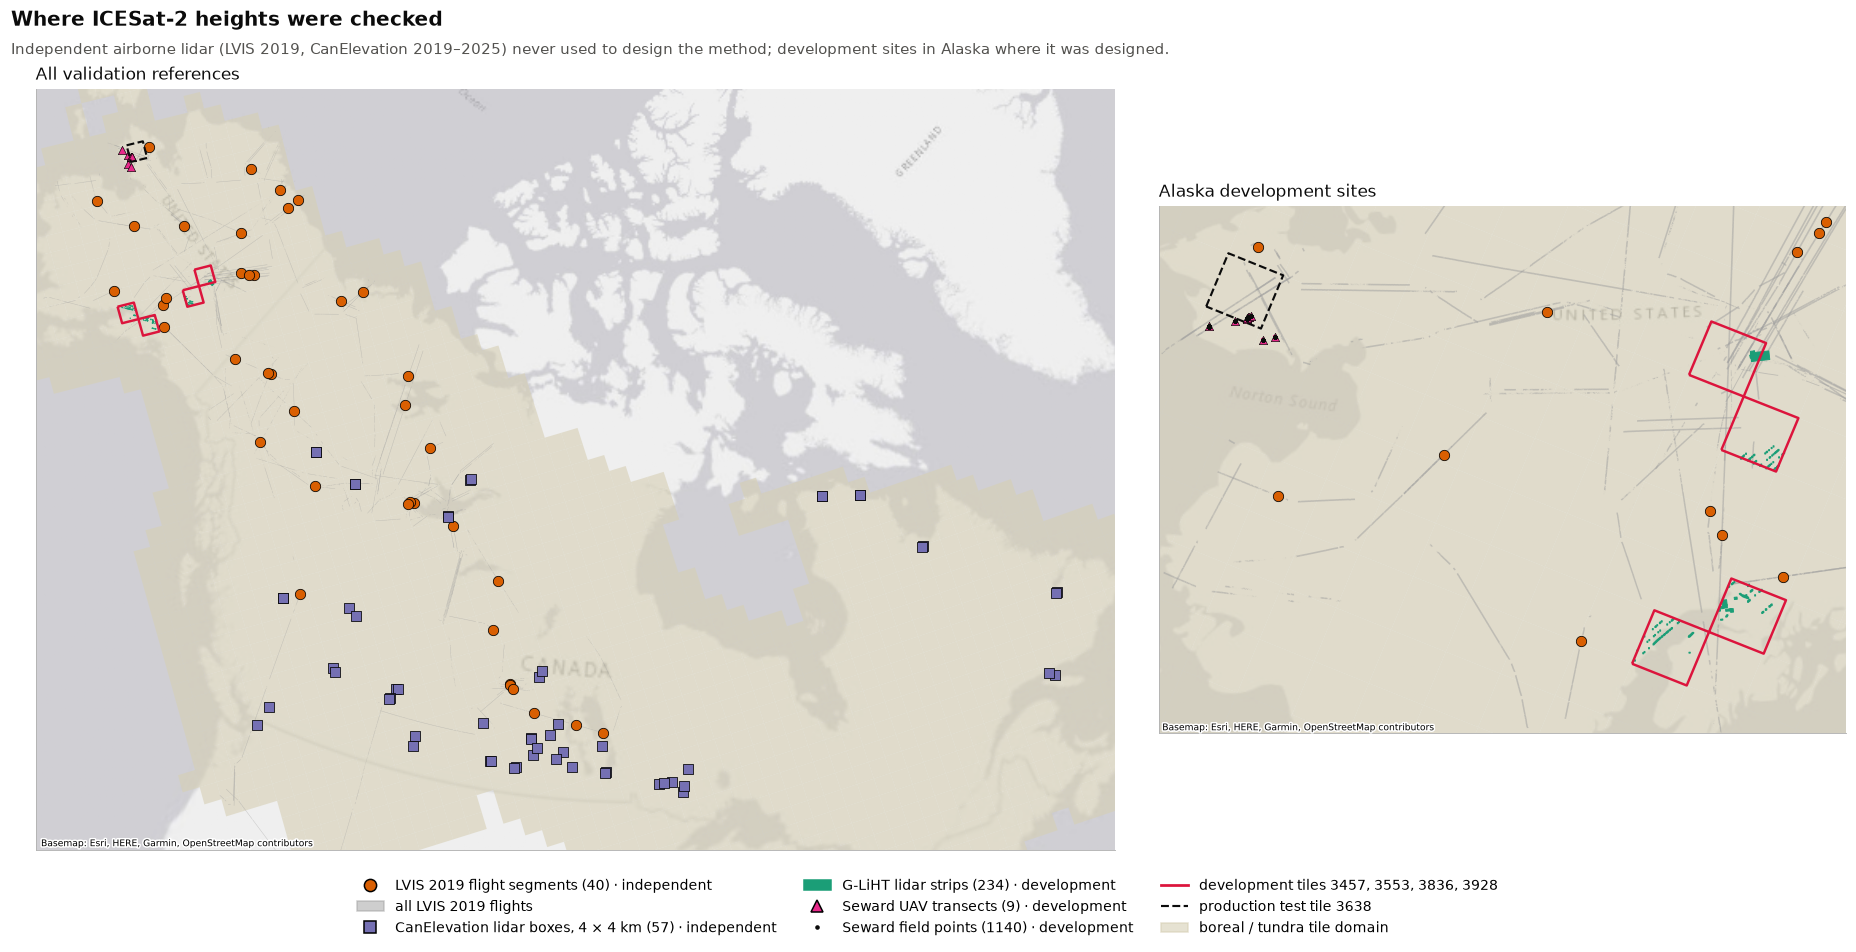

In [3]:
sites = pl.validation_sites(WORK, cfg["paths"]["boreal_tiles"], seward_dir=cfg["paths"]["seward_dir"])
fig = pl.validation_map(sites, ps.add_basemap, ps.map_axes)
pl.lede(fig, "Where ICESat-2 heights were checked", "Independent airborne lidar (LVIS 2019, CanElevation 2019–2025) never used to design the method; development sites in Alaska where it was designed.")
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / "11_validation_map.png", bbox_inches="tight")

## 1 · Short vegetation is no longer inflated, and tall forest is less underestimated

**Take-home.** Over vegetation shorter than 2 m (tundra, shrubs, bare ground), today's ICESat-2 heights are on average
**0.8–2.2 m too tall** at the five references; with relabelled photons (v0.6) the overestimate drops to **0.0–0.9 m**
(CanElevation +1.0 → +0.3 m; G-LiHT +2.2 → +0.9 m; Seward drone +1.7 → +0.1 m). In forest taller than 10 m, today's heights
are **3.4–3.9 m too short** against lidar canopy-height models (CanElevation, G-LiHT); v0.6 is **2.4–2.7 m too short**, and the
tallest forest (where most carbon is) gains most: 20 m+ forest moves from **−4.7 to −2.9 m** (CanElevation) and from **−6.7 to
−3.5 m** (G-LiHT). Against LVIS waveform lidar our forest heights read about 2 m taller than LVIS, where today's are within
1.7 m of it; LVIS is weighed less. Between versions: v0.4 found the ground on slopes and stopped calling forest bare; v0.5–v0.6
stopped stray photons below the surface from pulling the ground down, which lowered short-vegetation heights further. v0.4
remains ~0.2 m closer in CanElevation tall forest (−2.2 vs −2.4 m), because under very dense canopy the ground still
sometimes starts on a low canopy layer (LOG, 18 Oct).


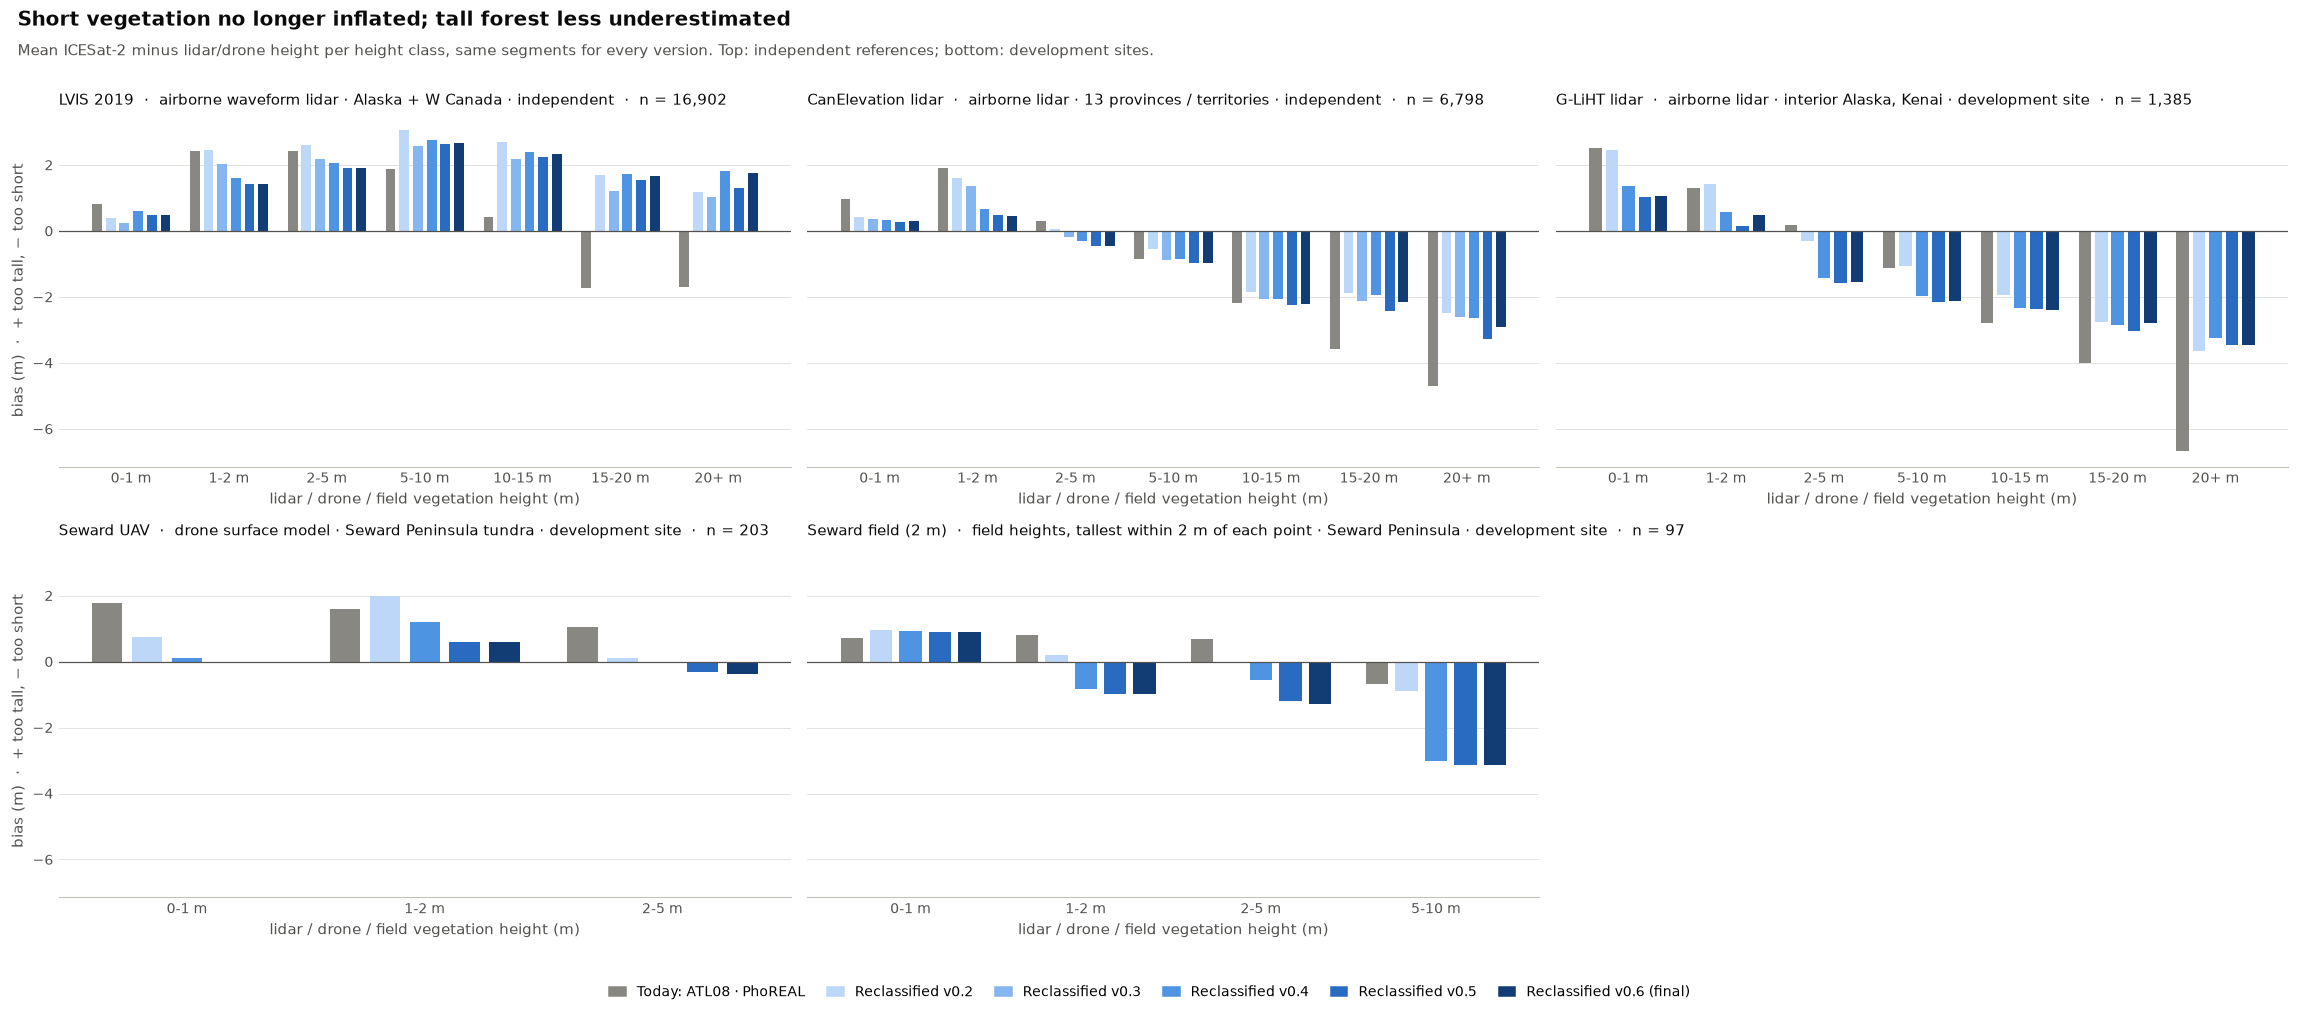

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(21, 8.4), sharey=True)
for ax, ref in zip(axes.ravel(), pl.REFS):
    vs = pl.versions_for(d, ref)
    tab = K[K.reference == ref].rename(columns={"height_class": "cat"})
    cats = [c for c in pl.CLASS_LABELS if c in set(tab.cat.astype(str))]
    tab = tab.assign(cat=tab.cat.astype(str))
    pl.grouped_bars(ax, tab, cats, vs, "bias")
    pl.style_axes(ax, "bias (m)  ·  + too tall, − too short" if ax in axes[:, 0] else None)
    n = int(pl.common(d, ref).shape[0])
    ax.set_title(f"{ref}  ·  {pl.REF_NOTE[ref]}  ·  n = {n:,}", fontsize=10, color=pl.INK, loc="left")
    ax.set_xlabel("lidar / drone / field vegetation height (m)", color=pl.INK2)
for ax in axes.ravel()[len(pl.REFS):]:
    ax.axis("off")
pl.lede(fig, "Short vegetation no longer inflated; tall forest less underestimated", "Mean ICESat-2 minus lidar/drone height per height class, same segments for every version. Top: independent references; bottom: development sites.")
pl.legend_row(fig, pl.VERSIONS)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / "11_bias_by_height.png", bbox_inches="tight")

## 2 · Far fewer invented shrubs; a small share of forest is called bare

**Take-home.** Today's heights put more than 2 m of vegetation on **14–39 %** of segments where the lidar or drone sees less than
1 m (bare ground, tundra). Relabelling (v0.6) cuts this by **half to five-sixths**, to **4–10 %**, at every reference
(CanElevation 14 → 4 %, G-LiHT 30 → 10 %, Seward drone 39 → 7 %). The cost is forest called bare (0 m): today's product does so
for about 1 % of forest segments, v0.6 for **2 % (LVIS), 5 % (CanElevation) and 8 % (G-LiHT)**. v0.3 did so for 6–8 % on the
independent references; since v0.4, 0 m is written only when vegetation would have been detected and none was.


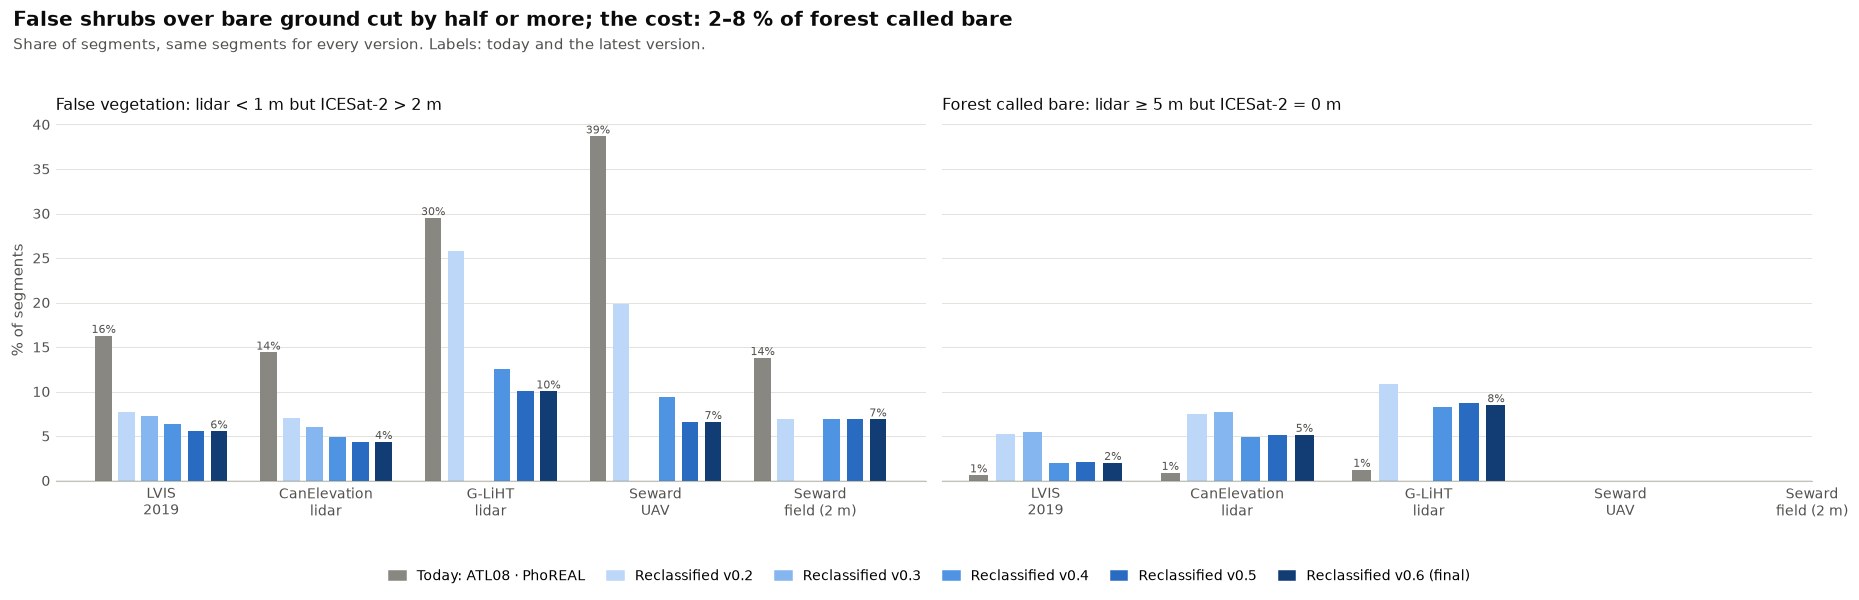

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), sharey=True)
for ax, col, title in [(axes[0], "spurious_veg", "False vegetation: lidar < 1 m but ICESat-2 > 2 m"),
                       (axes[1], "forest_at_0m", "Forest called bare: lidar ≥ 5 m but ICESat-2 = 0 m")]:
    tab = S.rename(columns={"reference": "cat"}).assign(pct=lambda x: 100 * x[col])
    pl.grouped_bars(ax, tab, pl.REFS, pl.VERSIONS, "pct", fmt=lambda v: f"{v:.0f}%", label_versions=(pl.TODAY, pl.LATEST))
    pl.style_axes(ax, "% of segments" if ax is axes[0] else None)
    ax.set_title(title, fontsize=10.5, color=pl.INK, loc="left")
    ax.set_xticks(range(len(pl.REFS)), [r.replace(" ", "\n", 1) for r in pl.REFS])
pl.lede(fig, "False shrubs over bare ground cut by half or more; the cost: 2–8 % of forest called bare", "Share of segments, same segments for every version. Labels: today and the latest version.")
pl.legend_row(fig, pl.VERSIONS, y=-0.04)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(FIG / "11_false_vegetation_and_zeros.png", bbox_inches="tight")

## 3 · Agreement with lidar improves; one tundra segment shows the remaining risk

**Take-home.** Each panel shows every 30 m segment (darker = more segments); the diagonal is perfect agreement. With relabelled
photons the vertical smear of false heights above bare ground (left edge of each panel) thins out, and agreement rises from
**r² 0.72 to 0.77** against CanElevation and from **0.39 to 0.56** against G-LiHT, with lower RMSE at both (3.9 → 3.7 m;
5.9 → 5.1 m). Against LVIS r² rises slightly (0.42 → 0.47) and RMSE grows (5.3 → 5.9 m). On the Seward tundra the mean
overestimate disappears (+1.5 → 0.0 m against the drone), but **one segment is reported at 38 m** over < 2 m tundra; it alone
raises the drone RMSE above today's (2.9 vs 2.4 m; without it 1.2 vs 2.3 m) and the field RMSE to 4.1 m. A plausibility cap on
heights over tundra is the obvious guard for production.


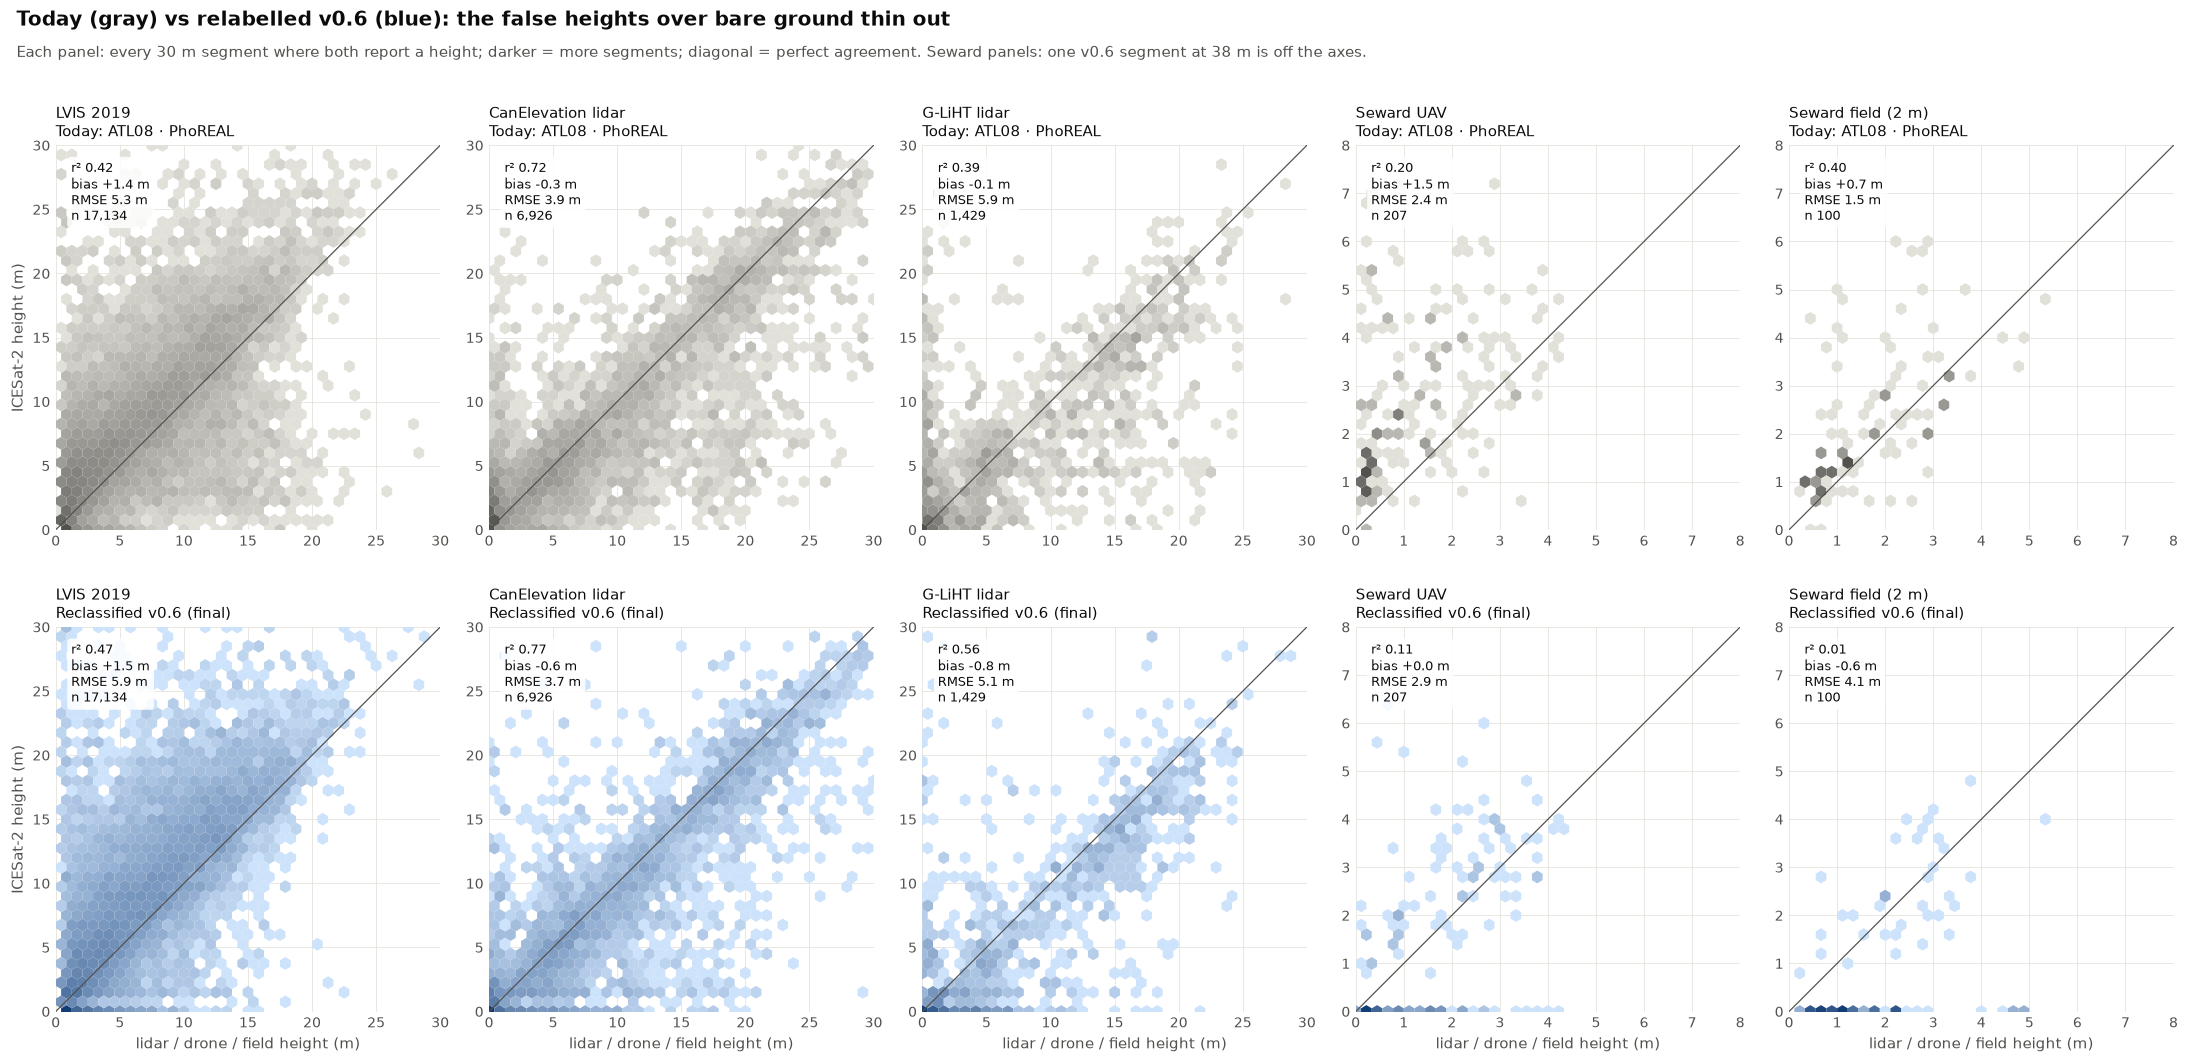

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9.4))
for j, ref in enumerate(pl.REFS):
    g = d[d.reference == ref].dropna(subset=[pl.TODAY, pl.LATEST])
    for i, v in enumerate([pl.TODAY, pl.LATEST]):
        pl.hexscatter(axes[i, j], g[v].to_numpy(), g.ref_h.to_numpy(), f"{ref}\n{pl.LABELS[v]}", lim=8 if ref.startswith("Seward") else 30,
                      color="#52514e" if v == pl.TODAY else pl.COLORS[pl.LATEST], light="#e1e0d9" if v == pl.TODAY else "#cde2fb")
        if j == 0: axes[i, j].set_ylabel("ICESat-2 height (m)", color=pl.INK2)
        if i == 1: axes[i, j].set_xlabel("lidar / drone / field height (m)", color=pl.INK2)
pl.lede(fig, f"Today (gray) vs relabelled {pl.LATEST} (blue): the false heights over bare ground thin out", "Each panel: every 30 m segment where both report a height; darker = more segments; diagonal = perfect agreement. Seward panels: one v0.6 segment at 38 m is off the axes.")
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=3.0); fig.savefig(FIG / "11_scatter_today_vs_best.png", bbox_inches="tight")

## 4 · Gains are largest where ICESat-2 sees least

**Take-home.** ICESat-2 fires three strong and three weak beams (a weak beam carries about a quarter of the energy), and by day
sunlight adds noise photons. On the independent references, relabelling raises agreement most where the signal is poorest:
**weak beams in daylight, r² 0.25 → 0.40**, and strong beams at night, 0.40 → 0.53. Weak beams at night stay the same
(0.67 → 0.68), and **strong beams in daylight lose some agreement (0.58 → 0.51)**.


version,today,v0.4,v0.5,v0.6
cat,,,,
night · strong beam,0.40,0.53,0.52,0.53
day · strong beam,0.58,0.51,0.51,0.51
night · weak beam,0.67,0.68,0.68,0.68
day · weak beam,0.25,0.38,0.41,0.40


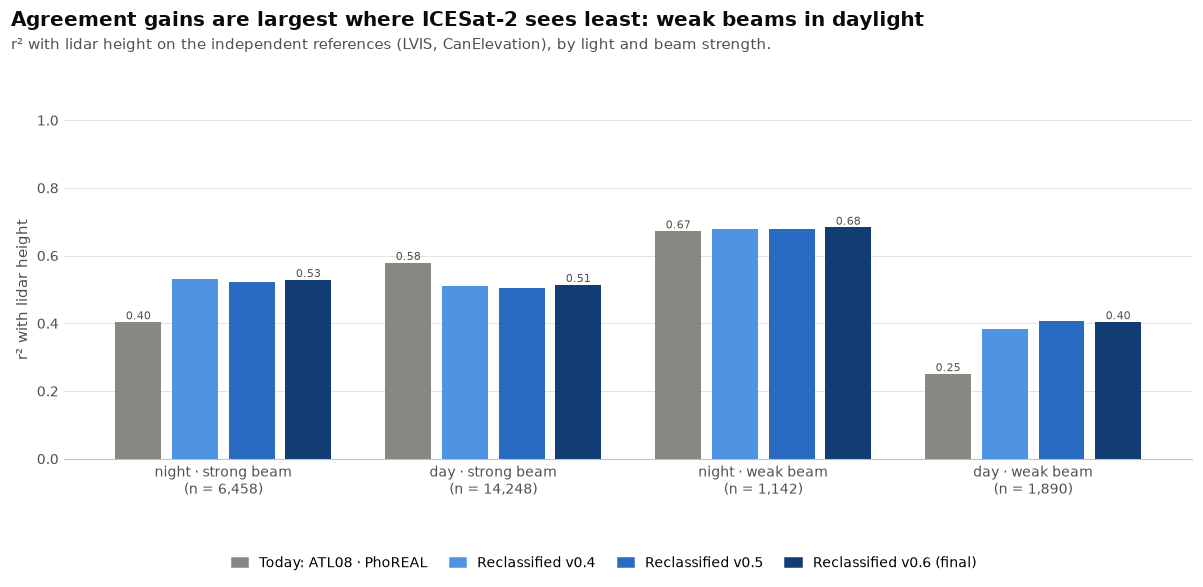

In [7]:
ind = d[d.independent].dropna(subset=[pl.TODAY, "v0.4", "v0.5", pl.LATEST]).assign(stratum=lambda x: x.light + " · " + x.beam + " beam")
order = ["night · strong beam", "day · strong beam", "night · weak beam", "day · weak beam"]
rows = [{"cat": st, "version": v, "r2": val.r_squared(g[v], g.ref_h), "n": len(g)} for st, g in ind.groupby("stratum") for v in (pl.TODAY, "v0.4", "v0.5", pl.LATEST)]
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(11, 4.4))
pl.grouped_bars(ax, R, order, [pl.TODAY, "v0.4", "v0.5", pl.LATEST], "r2", fmt=lambda v: f"{v:.2f}", label_versions=(pl.TODAY, pl.LATEST))
pl.style_axes(ax, "r² with lidar height", zero_line=False); ax.set_ylim(0, 1)
ax.set_xticks(range(len(order)), [f"{o}\n(n = {int(R[R.cat == o].n.iloc[0]):,})" for o in order])
pl.lede(fig, "Agreement gains are largest where ICESat-2 sees least: weak beams in daylight", "r² with lidar height on the independent references (LVIS, CanElevation), by light and beam strength.")
pl.legend_row(fig, [pl.TODAY, "v0.4", "v0.5", pl.LATEST], y=-0.06)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(FIG / "11_r2_by_signal.png", bbox_inches="tight")
R.pivot(index="cat", columns="version", values="r2").reindex(order).round(2)

## 5 · The trade-off: fewer segments get a height

**Take-home.** Today's product gives a height to **72–94 %** of segments; v0.6 gives one to **50–64 %**. Where there are too few
photons to tell vegetation from bare ground, mostly weak beams in daylight, our versions report "no height" instead of
guessing. Fewer but more trustworthy training samples is an acceptable trade-off: the multi-year biomass models already have
more ICESat-2 samples than they can use.


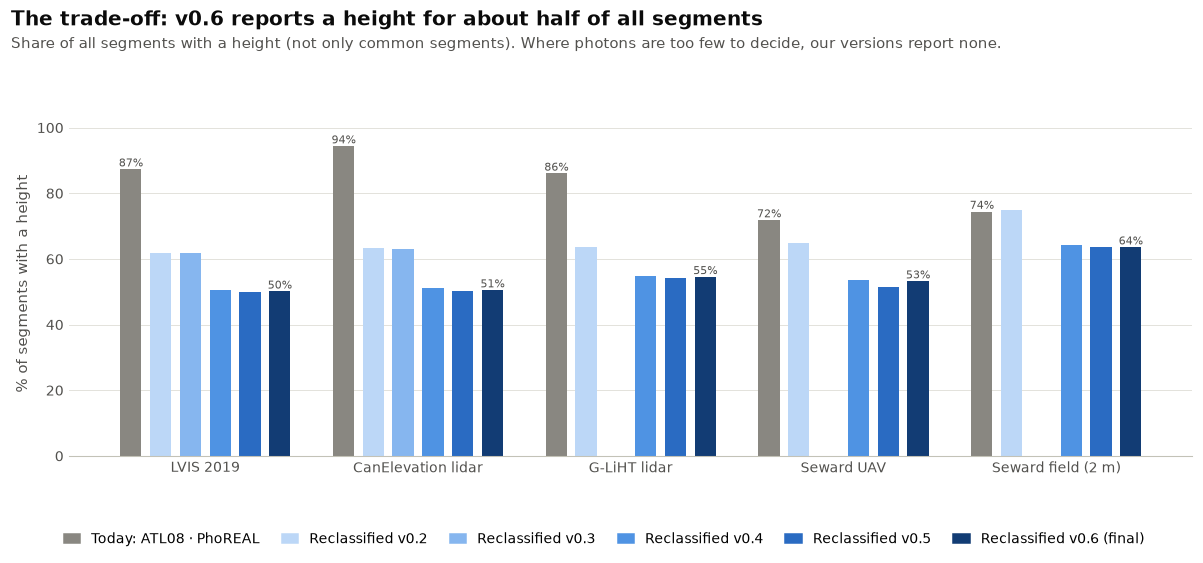

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
tab = S.rename(columns={"reference": "cat"}).assign(pct=lambda x: 100 * x.coverage)
pl.grouped_bars(ax, tab, pl.REFS, pl.VERSIONS, "pct", fmt=lambda v: f"{v:.0f}%", label_versions=(pl.TODAY, pl.LATEST))
pl.style_axes(ax, "% of segments with a height", zero_line=False); ax.set_ylim(0, 105)
pl.lede(fig, f"The trade-off: {pl.LATEST} reports a height for about half of all segments", "Share of all segments with a height (not only common segments). Where photons are too few to decide, our versions report none.")
pl.legend_row(fig, pl.VERSIONS, y=-0.06)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(FIG / "11_coverage.png", bbox_inches="tight")

## Bottom line

**Relabelling ICESat-2's photons makes its vegetation heights more trustworthy at both ends of the height range, and v0.6 is
the version to train the biomass maps with.** Against discrete-return lidar never used to build the method (CanElevation, 13
Canadian provinces and territories), false shrubs over bare ground fall from 14 % to 4 % of segments, the short-vegetation
overestimate from +1.0 to +0.3 m, and the underestimate of 20 m+ forest from −4.7 to −2.9 m; r² rises from 0.73 to 0.77. The
development sites agree (G-LiHT false shrubs 30 → 10 %, 20 m+ forest −6.7 → −3.5 m; Seward tundra bias +1.5 → 0.0 m). About
half of segments get no height, which the multi-year models can afford. Two things to watch in production: tall forest is
still 2–3 m too short (partly because the ground under dense canopy sits too high), and rare implausible heights over tundra
(one 38 m segment at Seward) call for a plausibility cap. Numbers on the same segments for today and v0.6:


In [9]:
cols = {"n_common": "segments compared", "bias_short_0-2m": "bias, lidar < 2 m (m)", "bias_tall_10m+": "bias, lidar ≥ 10 m (m)",
        "rmse": "RMSE (m)", "r2": "r²", "spurious_veg": "false vegetation", "forest_at_0m": "forest called bare", "coverage": "coverage"}
T = S[S.version.isin([pl.TODAY, pl.LATEST])].assign(version=lambda x: x.version.map(pl.LABELS)).set_index(["reference", "version"])[list(cols)].rename(columns=cols)
for c in ("false vegetation", "forest called bare", "coverage"):
    T[c] = (100 * T[c]).map(lambda v: f"{v:.0f} %" if np.isfinite(v) else "n/a (< 10 segments)")
T.round(2)

segments compared  \
reference          version                                        
LVIS 2019          Today: ATL08 · PhoREAL                 16902   
                   Reclassified v0.6 (final)              16902   
CanElevation lidar Today: ATL08 · PhoREAL                  6798   
                   Reclassified v0.6 (final)               6798   
G-LiHT lidar       Today: ATL08 · PhoREAL                  1385   
                   Reclassified v0.6 (final)               1385   
Seward UAV         Today: ATL08 · PhoREAL                   203   
                   Reclassified v0.6 (final)                203   
Seward field (2 m) Today: ATL08 · PhoREAL                    97   
                   Reclassified v0.6 (final)                 97   

                                              bias, lidar < 2 m (m)  \
reference          version                                            
LVIS 2019          Today: ATL08 · PhoREAL                      1.23   
                   Reclassified v0.6 (final)                   0.73   
CanElevation lidar Today: ATL08 · PhoREAL                      1.03   
                   Reclassified v0.6 (final)                   0.30   
G-LiHT lidar       Today: ATL08 · PhoREAL                      2.24   
                   Reclassified v0.6 (final)                   0.92   
Seward UAV         Today: ATL08 · PhoREAL                      1.72   
                   Reclassified v0.6 (final)                   0.14   
Seward field (2 m) Today: ATL08 · PhoREAL                      0.76   
                   Reclassified v0.6 (final)                  -0.02   

                                              bias, lidar ≥ 10 m (m)  \
reference          version                                             
LVIS 2019          Today: ATL08 · PhoREAL                      -0.16   
                   Reclassified v0.6 (final)                    2.15   
CanElevation lidar Today: ATL08 · PhoREAL                      -3.40   
                   Reclassified v0.6 (final)                   -2.40   
G-LiHT lidar       Today: ATL08 · PhoREAL                      -3.95   
                   Reclassified v0.6 (final)                   -2.75   
Seward UAV         Today: ATL08 · PhoREAL                        NaN   
                   Reclassified v0.6 (final)                     NaN   
Seward field (2 m) Today: ATL08 · PhoREAL                        NaN   
                   Reclassified v0.6 (final)                     NaN   

                                              RMSE (m)    r² false vegetation  \
reference          version                                                      
LVIS 2019          Today: ATL08 · PhoREAL         5.27  0.42             16 %   
                   Reclassified v0.6 (final)      5.92  0.47              6 %   
CanElevation lidar Today: ATL08 · PhoREAL         3.85  0.73             14 %   
                   Reclassified v0.6 (final)      3.65  0.77              4 %   
G-LiHT lidar       Today: ATL08 · PhoREAL         5.79  0.41             30 %   
                   Reclassified v0.6 (final)      4.98  0.58             10 %   
Seward UAV         Today: ATL08 · PhoREAL         2.35  0.21             39 %   
                   Reclassified v0.6 (final)      2.88  0.11              7 %   
Seward field (2 m) Today: ATL08 · PhoREAL         1.56  0.40             14 %   
                   Reclassified v0.6 (final)      4.16  0.01              7 %   

                                               forest called bare coverage  
reference          version                                                  
LVIS 2019          Today: ATL08 · PhoREAL                     1 %     87 %  
                   Reclassified v0.6 (final)                  2 %     50 %  
CanElevation lidar Today: ATL08 · PhoREAL                     1 %     94 %  
                   Reclassified v0.6 (final)                  5 %     51 %  
G-LiHT lidar       Today: ATL08 · PhoREAL                     1 %     86 %  
           

## Appendix 1 · How much of the change is binning rather than labelling?

The **control** uses NASA's photon labels, as today does, but our own 30 m binning. If the control looks like today, the
improvements come from relabelling the photons, not from the binning.

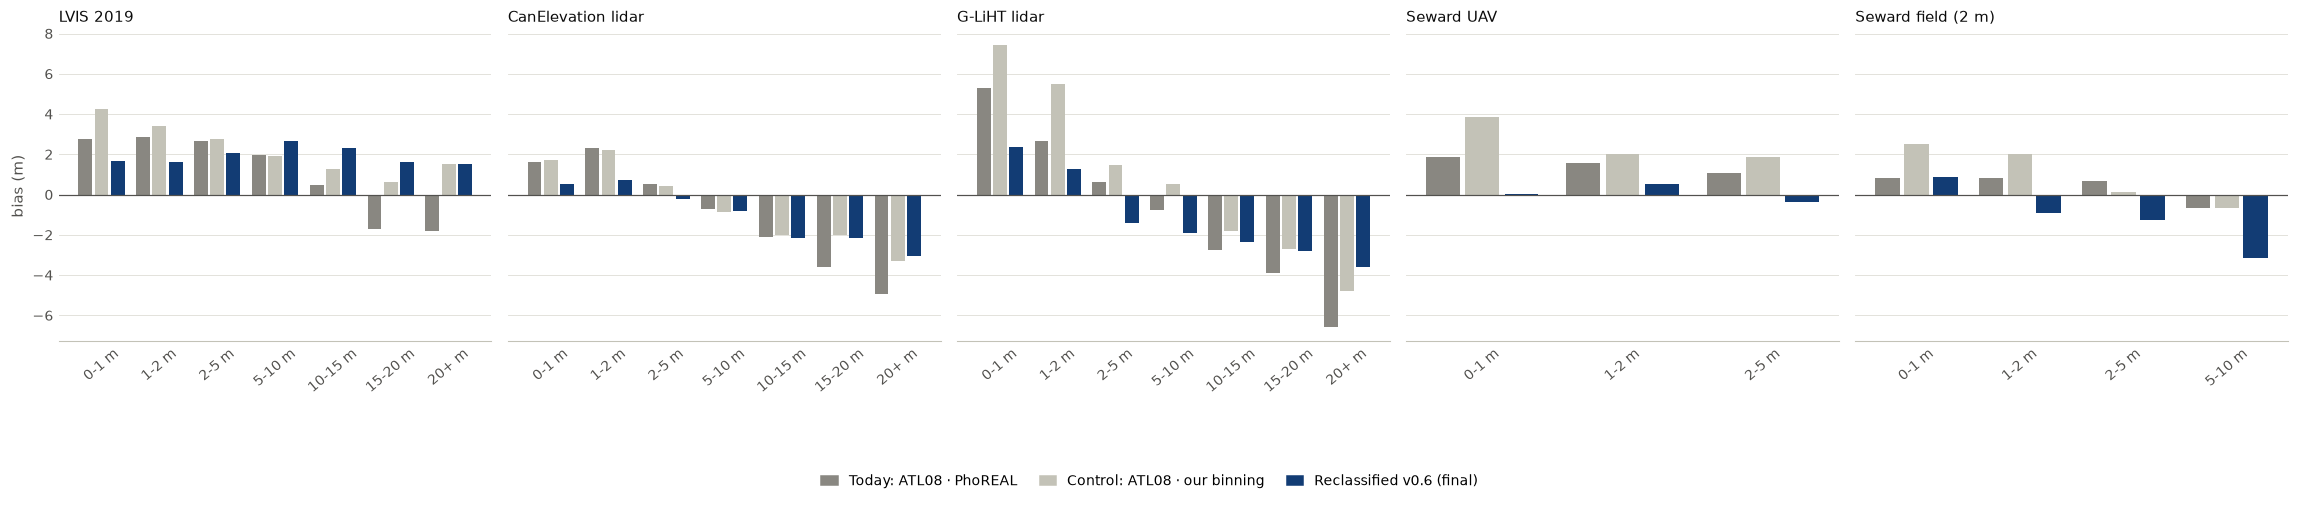

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(21, 3.8), sharey=True)
vs3 = [pl.TODAY, pl.CONTROL, pl.LATEST]
for ax, ref in zip(axes, pl.REFS):
    g = d[d.reference == ref].dropna(subset=vs3)
    rows = [{"cat": str(cl), "version": v, "bias": (gg[v] - gg.ref_h).mean()} for cl, gg in g.groupby("height_class", observed=True) for v in vs3]
    tab = pd.DataFrame(rows, columns=["cat", "version", "bias"]); cats = [c for c in pl.CLASS_LABELS if c in set(tab.cat)]
    pl.grouped_bars(ax, tab, cats, vs3, "bias")
    pl.style_axes(ax, "bias (m)" if ax is axes[0] else None); ax.set_title(ref, fontsize=10, color=pl.INK, loc="left")
    ax.tick_params(axis="x", rotation=40)
pl.legend_row(fig, vs3, y=-0.12)
fig.tight_layout(); fig.savefig(FIG / "11_appendix_binning.png", bbox_inches="tight")

## Appendix 2 · Steep terrain

On slopes, an 11 m laser footprint returns ground photons over several metres of height, which older versions mistook for
vegetation. Bias by along-track ground slope, independent references, today vs v0.6 (common segments).

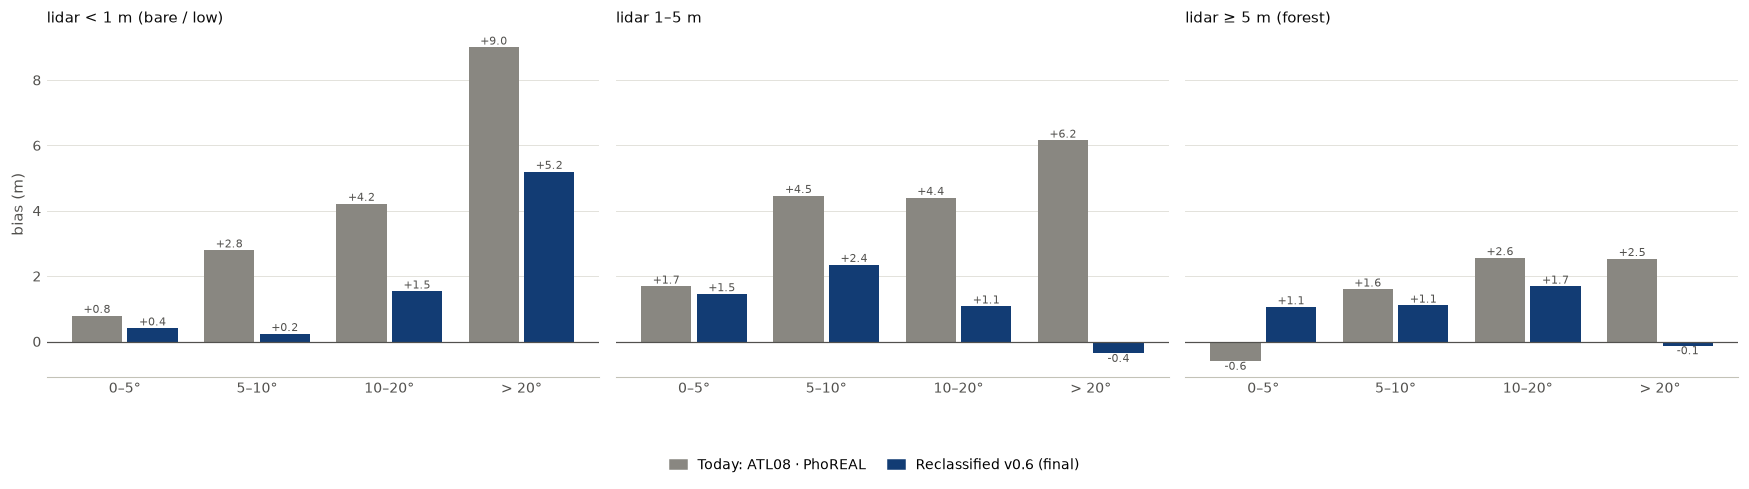

In [11]:
ind = d[d.independent].dropna(subset=[pl.TODAY, pl.LATEST, "slope_deg"])
ind = ind.assign(slope=pd.cut(ind.slope_deg, [0, 5, 10, 20, 90], right=False, labels=["0–5°", "5–10°", "10–20°", "> 20°"]),
                 veg=np.where(ind.ref_h < 1, "lidar < 1 m (bare / low)", np.where(ind.ref_h < 5, "lidar 1–5 m", "lidar ≥ 5 m (forest)")))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, veg in zip(axes, ["lidar < 1 m (bare / low)", "lidar 1–5 m", "lidar ≥ 5 m (forest)"]):
    g = ind[ind.veg == veg]
    rows = [{"cat": str(s), "version": v, "bias": (gg[v] - gg.ref_h).mean(), "n": len(gg)} for s, gg in g.groupby("slope", observed=True) for v in (pl.TODAY, pl.LATEST)]
    tab = pd.DataFrame(rows, columns=["cat", "version", "bias", "n"]); cats = [c for c in ["0–5°", "5–10°", "10–20°", "> 20°"] if c in set(tab.cat)]
    pl.grouped_bars(ax, tab, cats, [pl.TODAY, pl.LATEST], "bias", fmt=lambda v: f"{v:+.1f}", label_versions=(pl.TODAY, pl.LATEST))
    pl.style_axes(ax, "bias (m)" if ax is axes[0] else None); ax.set_title(veg, fontsize=10, color=pl.INK, loc="left")
pl.legend_row(fig, [pl.TODAY, pl.LATEST], y=-0.08)
fig.tight_layout(); fig.savefig(FIG / "11_appendix_slope.png", bbox_inches="tight")

## Appendix 3 · Data and definitions

- **Segments:** 30 m along an ICESat-2 orbit track, June–September; ICESat-2 data release 007.
- **Reference height:** 98th percentile of the 1 m lidar or drone canopy height model in the 30 m × 11 m footprint (LVIS: mean
  waveform RH98 along the segment; over bare ground LVIS reads ~0.5–1 m). **Seward field (2 m):** tallest field-measured
  height within 2 m of each field point inside the segment, maximum over those points (182 segments; a point survey, not a
  wall-to-wall model, so it samples the segment more sparsely than the drone model).
- **Versions:** methods document, section 8 (`docs/atl03_reclassification_methods.md`); decisions and evidence:
  `docs/atl03_reclassification_LOG.md`.
- **Source notebooks:** 01 (Seward), 05 (G-LiHT), 09 (LVIS), 10 (CanElevation); v0.3 was not run on the development sites, and v0.1
  predates the run folders.
- Tables behind the figures: `runs/v0.6/summary_all_references.csv`, `runs/v0.6/by_class_all_references.csv`; map: `runs/v0.6/figures/11_validation_map.png`.